Tareq El Kajjyouy

> Nature uses only the longest threads to weave her patterns, so that each small piece of her fabric reveals the organization of the entire tapestry.
- Richard P. Feynman

# **SCHRÖDINGER'S EQUATION**
## Motivation
The Schrödinger equation is considered in this study. Its connection with classical, Lagrangian, and analytical mechanics provides a relevant context for applying Model Order Reduction techniques to a quantum-mechanical system.

## Model Order Reduction for the Schrödinger Equation
This work presents the reasoning underlying the main modelling choices and the code implementation used to obtain the results. The analysis addresses the numerical simulation of an electron confined within a bi-crystal disk $\Omega$, governed by the time-dependent Schrödinger equation. The objective is to construct a **Reduced Order Model** to efficiently approximate the wave function $\Psi$ and analyze the electron's probability distribution. The system is modeled by the Schrödinger equation:
$$i\hbar\frac{\partial\Psi}{\partial t}=-\frac{\hbar^{2}}{2m}\Delta\Psi+V_{\mu}\Psi$$

where the parametrized potential $V_{\mu}$ (with $\mu=[E, \Delta V_{0}]$) is given by:

$$V(x; \mu)=E^{\top}x+\Delta V_{0}1_{[0,+\infty)}(x_{2})$$

In [1]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
clc()

In [2]:
# # Downloading the dataset
# import gdown
# gdown.download(id = "1LSww0NSGn-6pd_fkQosU9Uw2qxz3dp3a", output = "datageneration.npz", quiet=False)

In [3]:
# Geometry definition
domain = fe.circle((0, 0), 1.0/np.pi)                             # Define the circular domain with radius 1/pi, as specified
mesh = fe.mesh(domain, stepsize = 0.02)                           # Generate the mesh using a small step size
Vh = fe.space(mesh, 'CG', 1)                                      # Use continuous Galerkin elements (CG) with polynomial degree 1
nh = Vh.dim()                                                     # Determine the dimension Nh
clc()


## DEFINE THE FULL ORDER MODEL (FOM)
def FOMsolver(E, deltaV0, steps = 99, dt = 1e-3):                                          # Define the full-order model solver
  from fenics import inner, grad, dx, div, assemble, DirichletBC, Constant, Expression     # Import the required libraries
  from scipy.sparse.linalg import spsolve                                                  # Import the required libraries
  from scipy.sparse import bmat                                                            # Import the required libraries


# System assumptions
  potential = fe.interpolate(lambda x: E*(x[0]/np.sqrt(2.0) - x[1]/np.sqrt(2.0)) + deltaV0*(x[1] > 0), Vh)  # Define the electric-potential field V_mu(x)
  # The potential is defined by the electric-field vector E and the condition $\Delta V_0>0$
  S = fe.assemble(lambda u, v: inner(grad(u), grad(v))*dx, Vh)  # Assemble the stiffness matrix
  M = fe.assemble(lambda u, v: u*v*dx, Vh)                      # Assemble the mass matrix
  V = fe.assemble(lambda u, v: potential*u*v*dx, Vh)            # Assemble the potential matrix


# Boundary conditions
  bc = fe.DirichletBC(lambda x: True, 0.0)                      # Define the boundary conditions
  B = S + V                                                     # sum of the two matrices
  B = fe.applyBCs(B, Vh, bc)                                    # Impose homogeneous Dirichlet boundary conditions
  M = fe.applyBCs(M, Vh, bc)                                    # Impose homogeneous Dirichlet boundary conditions
# The matrices S, V, and M are set to zero on the boundary degrees of freedom


# Real and imaginary components
  A = bmat([[M, -dt*B], [dt*B, M]])                             # Matrix obtained from the Backward Euler discretization
  M2 = bmat([[M, 0*M], [0*M, M]])                               # Use zero blocks with the same dimensions as M


# Initial-condition definition and vector assembly
  u0_real = fe.interpolate(lambda x: np.exp(-100*(x[0]**2+x[1]**2)), Vh)   # Real part of the initial condition
  u0_imag = fe.interpolate(0.0, Vh)                                        # Imaginary part of the initial condition, set to zero
  u0_real_vec = fe.dofs(u0_real)                                           # Represent the real part of the initial condition as a vector
  u0_imag_vec = fe.dofs(u0_imag)                                           # Represent the imaginary part of the initial condition as a vector
  states = [np.concatenate((u0_real_vec, u0_imag_vec))]                    # Combine the real and imaginary components into a single vector


# Matrix assembly over the time steps
  for n in range(steps):                                                    # Iterate over the time intervals
    now = states[-1]
    rhs = M2 @ now                                                          # Use the most recent state
    rhs[:nh] = fe.applyBCs(rhs[:nh], Vh, bc)                                # Enforce homogeneous boundary conditions on the updated right-hand side; spsolve solves the linear system
    rhs[nh:] = fe.applyBCs(rhs[nh:], Vh, bc)
    next = spsolve(A, rhs)
    states.append(next)                                                     # Append the updated state
  clc()
  return np.stack(states)                                                   # Convert the list into a matrix (rows = time steps; columns = FEM degrees of freedom)


## Auxiliary functions
from fenics import dx
M = fe.assemble(lambda u, v: u*v*dx, Vh)                                              # Mass matrix in integral form
clc()

# Define the probability density function $p_t$
def probabilities(u):
  unnormalized_probabilities = (u.reshape(-1, 2, nh)**2).sum(axis = 1)                # Separate the real and imaginary components at each time instant and compute the squared magnitude
  integrals = (unnormalized_probabilities @ M).sum(axis = -1)                         # Compute the integral of the probability density
  return unnormalized_probabilities/integrals.reshape(-1, 1)                          # Return the probability density p_t

# Define the probability functional (double integral)
def caught(prob):
  T = 0.1                                                          # Set the final simulation time T = dt * steps
  times = np.linspace(0, T, 100)                                   # Define the time axis
  indicator = fe.dofs(fe.interpolate(lambda x: x[1]>0, Vh))        # Define the indicator function for the upper region, x_2 > 0
  return (prob @ M @ indicator).mean()                             # Evaluate P by computing the spatial integral and averaging over time

### **Data Generation**

A total of **30 FOM simulations** were generated. The simulations were divided equally into training and testing sets. For each sample, the parameters

$$
E \in [0,1000], \qquad \Delta V_0 \in [0,1000]
$$

were randomly drawn from a uniform distribution.

The generated dataset consists of: $n_{\text{samples}}=30$ parameter matrix = $\mu \in \mathbb{R}^{30 \times 2}$, snapshot matrix = $u \in \mathbb{R}^{30 \times n_t \times 95}$, number of simulations = $30$, $n_t$ = $99$ and FOM dimension = $95$. The code solves the PDE 30 times, with each simulation corresponding to a different randomly selected parameter pair $(E,\Delta V_0)$. The dataset is then split into **15 training simulations** and **15 testing simulations** for the subsequent POD analysis and ROM construction.

1. Data generation is performed through a for loop with $n_{\text{samples}}$ iterations. The resulting matrices are $\mu$ and $u$.
2. $U_{train}$ is constructed from $u$ by selecting the training samples. After truncation, $u$ is reshaped into a two-dimensional matrix, as required for the SVD.
3. SVD is then applied, and the matrix $V$ is defined using the singular-value spectrum.

## Full order model

In [4]:
import os
import gdown
import numpy as np

FILENAME = 'Assignment1_Tareq.npz'
GOOGLE_DRIVE_LINK_OR_ID = 'https://drive.google.com/file/d/1bR9pulf_q6E_wNQ_dNhUHKF38KcKzOLG/view?usp=drive_link'

if 'drive.google.com/file/d/' in GOOGLE_DRIVE_LINK_OR_ID:
    GOOGLE_DRIVE_FILE_ID = GOOGLE_DRIVE_LINK_OR_ID.split('/d/')[1].split('/view')[0]
else:
    GOOGLE_DRIVE_FILE_ID = GOOGLE_DRIVE_LINK_OR_ID

if os.path.exists(FILENAME):
    print(f"Loading data from existing '{FILENAME}' file...")
    data_loaded = True
elif GOOGLE_DRIVE_FILE_ID and GOOGLE_DRIVE_FILE_ID != 'YOUR_GOOGLE_DRIVE_FILE_ID':
    print(f"Downloading '{FILENAME}' from Google Drive ID: {GOOGLE_DRIVE_FILE_ID}...")
    try:
        gdown.download(id=GOOGLE_DRIVE_FILE_ID, output=FILENAME, quiet=False)
        data_loaded = True
    except Exception as e:
        print(f"Error downloading file: {e}")
        data_loaded = False
else:
    print("No pre-saved data found or Google Drive ID provided. Proceeding with data generation.")
    data_loaded = False

if data_loaded:
    print(f"Loading data from '{FILENAME}'...")
    data = np.load(FILENAME)
    mu = data['mu']
    u = data['u']
    if 'Es_exceed' in data.files and 'P_exceed' in data.files and 'P_total' in data.files and 'Es_total' in data.files and 'P_results' in data.files:
        P_total = data['P_total']
        Es_total = data['Es_total']
        Es_exceed = data['Es_exceed']
        P_exceed = data['P_exceed']
        P_results = data['P_results']
    print("Data loaded successfully!")

Downloading...
From (original): https://drive.google.com/uc?id=1bR9pulf_q6E_wNQ_dNhUHKF38KcKzOLG
From (redirected): https://drive.google.com/uc?id=1bR9pulf_q6E_wNQ_dNhUHKF38KcKzOLG&confirm=t&uuid=76163ae2-b642-4849-ad7c-147292c58d28
To: /content/Assignment1_Tareq.npz
100%|██████████| 47.8M/47.8M [00:01<00:00, 30.6MB/s]


Loading data from 'Assignment1_Tareq.npz'...
Data loaded successfully!


## Data generation


In [5]:
if not data_loaded:
    print("Generating new data...")
    # Data generation
    # Parameter values are sampled in the interval [0, 1000]
    # The parameter vector contains E and V0

    nsamples = 30                                                                   # Number of samples
    muList = []                                                                    # List of parameter vectors
    uList = []                                                                     # List of FOM solutions associated with the parameter vectors
    for i in range(nsamples):
      E = 1000*np.random.rand()                                                    # Sample a random value in [0, 1] and scale it to [0, 1000]
      deltaV0 = 1000*np.random.rand()                                              # define Sample a random value in [0, 1] and scale it to [0, 1000]
      mu_current = np.array([E, deltaV0])                                          # Construct the parameter vector
      u_current = FOMsolver(mu_current[0], mu_current[1])                          # Pass E and deltaV0 as separate arguments
      muList.append(mu_current)                                                    # Append the value to the list
      uList.append(u_current)                                                      # Append the value to the list

    mu = np.stack(muList)
    u = np.stack(uList)

    print(f"The number of trajectories is {u.shape} (u)")
    print(f"The number of parameters is {mu.shape} (mu)")
else:
    print("Skipping data generation as data was loaded from file.")
    # mu and u are already loaded
    nsamples = mu.shape[0] # Determine nsamples from the loaded data

E = 1000*np.random.rand()                                                    # Sample a random value in [0, 1] and scale it to [0, 1000]
deltaV0 = 1000*np.random.rand()                                              # define Sample a random value in [0, 1] and scale it to [0, 1000]

Skipping data generation as data was loaded from file.


In [6]:
# nsamples = 30    # nsamples is set to 30, corresponding to the number of FOM simulations

# muList = []                              # Parameters list
# uList = []                               # Solution list
# for i in range(nsamples):
#     E = 1000* np.random.rand()           # (0, 1000)
#     deltaV0 = 1000 * np.random.rand()    # (0, 1000)
#     mu_current = np.array([E, deltaV0])  # Construct the parameter vector
#     u_current = FOMsolver(E, deltaV0)    # Compute the FOM solution for the sampled parameter values
#     muList.append(mu_current)
#     uList.append(u_current)
# mu = np.stack(muList)
# u = np.stack(uList)
# # The PDE is solved 30 times; each row corresponds to one PDE solution

# print(f"The dimension (Vh) is: {Vh.dim()}") # Vh.dim = 95
# print(f"The number of trajectories (u) is: {u.shape}, on which: 1st value = number of data (ndata), 2nd value = number of time instants (nt), 3rd value = number of degrees of freedom (nh).")
print(f'The dimension of the mu vector is: {mu.shape}')

The dimension of the mu vector is: (30, 2)


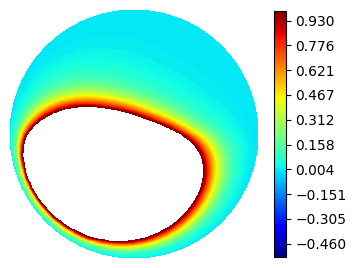

In [7]:
# Plot the solution at a selected time instant for a specified sample.
fe.multiplot(probabilities(u[1, -1, :]), (1, 1), Vh, colorbar = True, vmin = u.min(), vmax = u.max())

## Application of the SINGULAR VALUE DECOMPOSITION



In [8]:
from scipy.linalg import svd # Import the SVD routine
# nsamples denotes the total number of high-fidelity simulations; each sample corresponds to one FOM solution
# ntrain denotes the number of samples used to construct the model

ntrain = nsamples//2                                                    # Select the first 15 simulations
ndata, nt, nh = u.shape                                                 # u has dimensions ndata, nt, and nh; without time dependence, its shape would be ndata x nh
Utrain = (u[:ntrain]).reshape(ntrain*nt, nh).T                          # Construct the training snapshot matrix using the first ntrain samples and reshape it as required
# Reshape the data into matrix form
# The target matrix has dimensions nh x nsnapshots, where nsnapshots = ntrain x number of time steps
# Utrain is the snapshot matrix

# Compute the SVD
X, s, Yt = svd(Utrain, full_matrices = False) # 
# s = vector of the singular values (it contains all the singular values)
# X => left eigenvector matrix
# Yt => right eigenvector matrix
Utrain.shape, X.shape, s.shape, Yt.shape

((1990, 1500), (1990, 1500), (1500,), (1500, 1500))

In [9]:
nt

100

In [10]:
print(f"The snapshot matrix is expected to have some zero rows. This is due to the fact:")
Utrain

The snapshot matrix is expected to have some zero rows. This is due to the fact:


array([[ 3.97807744e-05,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.17369294e-04, -4.65224853e-04, -1.37119214e-04, ...,
        -1.09751793e-05, -7.67669697e-05, -1.42340702e-04],
       [ 1.24760860e-04, -3.41585590e-04,  2.45480483e-04, ...,
        -7.26643935e-06, -5.09021490e-05, -9.43967625e-05],
       ...,
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

In [11]:
print(f"The dimension of u is {u.shape}, on which: 1st value = number of data (ndata), 2nd value = number of time instants (nt), 3rd value = number of degrees of freedom (nh).")
print(" ")
print(f"The dimension of Utrain is {Utrain.shape}, on which: 1st value = number of degrees of freedom (nh), 2nd value = number of snapshots (ntrain * nt).")
print(" ")
print(f"The number of singular values is {len(s)}.")
print(" ")
print(f"The dimension of X is {X.shape}, on which: 1st value = number of degrees of freedom (nh), 2nd value = number of snapshots (ntrain * nt).")

print("X = complete eigenvector matrix; s = complete singular values; Utrain = ")

The dimension of u is (30, 100, 1990), on which: 1st value = number of data (ndata), 2nd value = number of time instants (nt), 3rd value = number of degrees of freedom (nh).
 
The dimension of Utrain is (1990, 1500), on which: 1st value = number of degrees of freedom (nh), 2nd value = number of snapshots (ntrain * nt).
 
The number of singular values is 1500.
 
The dimension of X is (1990, 1500), on which: 1st value = number of degrees of freedom (nh), 2nd value = number of snapshots (ntrain * nt).
X = complete eigenvector matrix; s = complete singular values; Utrain = 


## Extraction of the POD basis and number of modes to consider

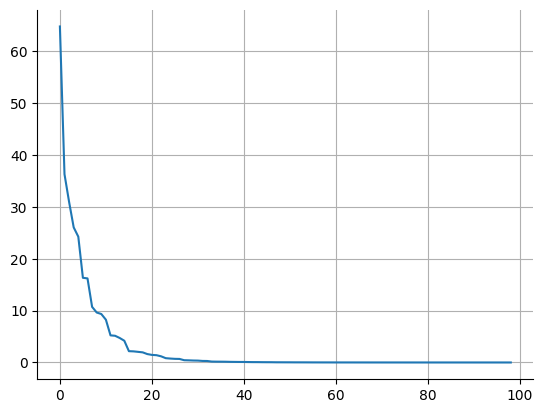

In [12]:
# Generate plot
plt.plot(s[1:100])  # Plot the singular values
# Use 50 to set the displayed range and 1 for PCA

# Customize the plot
plt.grid(True, which="both")
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

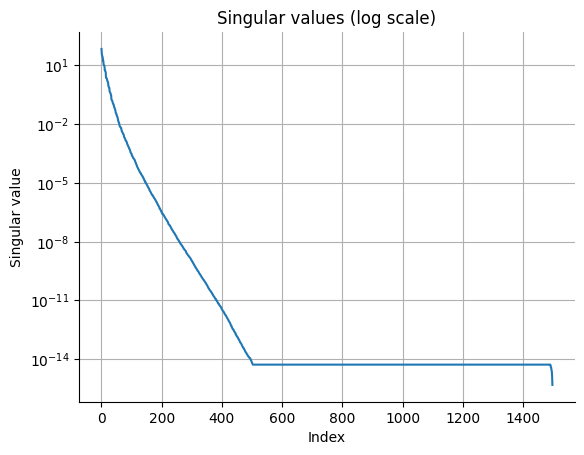

In [13]:
# Plot on a logarithmic scale
plt.plot(s[1:])
plt.yscale('log')

# Customize text
plt.xlabel('Index')
plt.ylabel('Singular value')
plt.title('Singular values (log scale)')

# Add grid and display the plot
plt.grid(True, which="both")
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

# The value of n is approximately 450; the plateau is identified from the singular-value spectrum

In [14]:
n = 30
# Number of basis functions selected from the behavior of the spectrum; an even value is used. The selected index corresponds to the region where the curve approaches zero.

In [15]:
u.shape

(30, 100, 1990)

In [16]:
Vn = X[:, :n]          # Truncate the left singular-vector matrix to n modes
print(f"The shape of Vn is expected to be {Vn.shape}, which shows how the dimension is like {X.shape} in terms of columns, but in terms of rows we truncate many eigenvectors because they have a low energy.")

The shape of Vn is expected to be (1990, 30), which shows how the dimension is like (1990, 1500) in terms of columns, but in terms of rows we truncate many eigenvectors because they have a low energy.


## Reduced Order Model development

The following stages are considered:

### 1. **ROM ANALYSIS**
1. The libraries and FOM values defined in the dataset are initialized. The functions `pot1` and `pot2` are then defined without explicit parameter dependence; the parameter values are subsequently supplied to the RBsolver. This allows the parameter values to be selected within the range of interest.
2. The affine parametrization of the system is defined through the function `RBstep`, which takes as input the value of $\Psi$ at a given time and the corresponding $\mu$.
3. The RBsolver is applied through a for loop that iterates over each time instant and evaluates `RBstep`. Each iteration performs a Backward Euler step. After the loop, the reconstructed solution $\tilde{u}_h$ is defined.

### 2. **EFFICIENCY ANALYSIS**
1. The efficiency analysis compares the FOM solver and the ROM solver. The elapsed time is measured between $t_0$ and $t_1$, corresponding to the execution of each solver separately for the same parameter vector $\mu$ and time-step value $dt$.

### 3. **ACCURACY ANALYSIS**
1. Determination of the relative error through direct application of the corresponding formula.
2. Plot of the error evolution over all time steps, using the same formula.
3. Analysis of the error distribution using a box plot.

### Realization of the ROM (Reduced order model)


In [17]:
# Define the required libraries
from fenics import inner, grad, dx, div, assemble, DirichletBC, Constant, Expression      # Import the libraries required by the FOM solver
from scipy.sparse.linalg import spsolve                                                   # Import the linear-system solver used by the FOM solver
from scipy.sparse import bmat                                                             # Import the sparse block-matrix utility used by the FOM solver
bc = fe.DirichletBC(lambda x: True, 0.0)

# Reinitialize the given values
potential = fe.interpolate(lambda x: E*(x[0]/np.sqrt(2.0) - x[1]/np.sqrt(2.0)) + deltaV0*(x[1] > 0), Vh)  # Define the electric-potential field V_mu(x)
V = fe.assemble(lambda u, v: potential*u*v*dx, Vh)                                                        # Assemble the potential matrix
M = fe.assemble(lambda u, v: u*v*dx, Vh)                                                                  # Assemble the mass matrix
S = fe.assemble(lambda u, v: inner(grad(u), grad(v))*dx, Vh)                                              # Assemble the stiffness matrix
M2 = bmat([[M, 0*M], [0*M, M]])                                                                           # Construct the block mass matrix for the real and imaginary components
# The matrix V also contains the potential contribution. The parameter dependence is separated
# from V so that matrix A is independent of the parameter values.


# Define the space using pot1 and pot2 only
# Define the independent spatial components associated with the parameter vector
pot1 = fe.interpolate(lambda x: (x[0]/np.sqrt(2.0) - x[1]/np.sqrt(2.0)), Vh)    # E component
pot2 = fe.interpolate(lambda x: 1.0*(x[1] > 0), Vh)                             # DeltaV0 component
# fe.interpolate projects the specified expression onto the space V_h
# pot1 and pot2 separate the spatial components from the parameter values
# pot1 and pot2 are independent of E and DeltaV0. They retain the same spatial definitions as before, with unit magnitude.


# Define the potential components independently of the parameters
# Assemble the potential matrices associated with E and deltaV0 (Nh x Nh)
Eh = fe.assemble(lambda u, v: pot1*u*v*dx, Vh)                                             # Discretize the integral contribution associated with E to assemble the matrix
deltaVh = fe.assemble(lambda u, v: pot2*u*v*dx, Vh)                                        # Discretize the integral contribution associated with E to assemble the matrix
# The required matrices are now available.
# The values of E and deltaV0 are supplied to the RBsolver.

# # Insert the boundary condition => to be removed
# bc = fe.DirichletBC(lambda x: True, 0.0)                      # defining the boundary condition
# R = fe.applyBCs(R, Vn, bc)                                    # Apply homogeneous Dirichlet boundary conditions
# M = fe.applyBCs(M, Vn, bc)                                    # Apply homogeneous Dirichlet boundary conditions


# Assemble the final effective matrices.
Stot  = bmat([[None, S], [-S, None]])                                                      # The subscript 'tot' indicates that both real and imaginary components are included
Ehtot = bmat([[None, Eh], [-Eh, None]])                                                    # The subscript 'tot' indicates that both real and imaginary components are included
deltaVhtot = bmat([[None, deltaVh], [-deltaVh, None]])                                     # The subscript 'tot' indicates that both real and imaginary components are included
# The full-order matrices required by the Backward Euler scheme are now assembled.
# S is parameter-independent.

# Define the boundary conditions
S = fe.applyBCs(S, Vh, bc)
M = fe.applyBCs(M, Vh, bc)
Eh = fe.applyBCs(Eh, Vh, bc)
deltaVh = fe.applyBCs(deltaVh, Vh, bc)

# Apply Galerkin projection to the required matrices (N x N)
Srb  = Vn.T @ Stot @ Vn # Stot has dimensions 1990 x 1990
Erb = Vn.T @ Ehtot @ Vn
deltaVrb = Vn.T @ deltaVhtot @ Vn
Mrb = Vn.T @ M2 @ Vn

# Reduced boundary-condition treatment (not used)
# Srb = fe.applyBCs(Srb, Vn, bc)
# Mrb = fe.applyBCs(Mrb, Vn, bc)
# Erb = fe.applyBCs(Erb, Vn, bc)
# deltaVrb = fe.applyBCs(deltaVrb, Vn, bc)

Srb.shape, Erb.shape, deltaVrb.shape, Mrb.shape

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling form ffc_form_e6fe2f6d559447784d4e273c082f0dc8668ca1d5

INFO:FFC:Compiler stage 1: Analyzing form(s)
INFO:FFC:-----------------------------------
DEBUG:FFC:  Preprocessing form using 'uflacs' representation family.
INFO:FFC:  
INFO:FFC:  Geometric dimension:       2
  Number of cell subdomains: 0
  Rank:                      2
  Arguments:                 '(v_0, v_1)'
  Number of coefficients:    1
  Coefficients:              '[f_11]'
  Unique elements:           'CG1(?,?), Vector<2 x CG1(?,?)>'
  Unique sub elements:       'CG1(?,?), Vector<2 x CG1(?,?)>'
  
INFO:FFC:  representation:    auto --> uflacs
INFO:FFC:  quadrature_rule:   auto --> default
INFO:FFC:  quadrature_degree: auto --> 3
INFO:FFC:  quadrature_degree: 3
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.0860562 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-------------------------

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling form ffc_form_797f5b8a558921976f103fe39a96895ac5a846d4

INFO:FFC:Compiler stage 1: Analyzing form(s)
INFO:FFC:-----------------------------------
DEBUG:FFC:  Preprocessing form using 'uflacs' representation family.
INFO:FFC:  
INFO:FFC:  Geometric dimension:       2
  Number of cell subdomains: 0
  Rank:                      2
  Arguments:                 '(v_0, v_1)'
  Number of coefficients:    0
  Coefficients:              '[]'
  Unique elements:           'CG1(?,?), Vector<2 x CG1(?,?)>'
  Unique sub elements:       'CG1(?,?), Vector<2 x CG1(?,?)>'
  
INFO:FFC:  representation:    auto --> uflacs
INFO:FFC:  quadrature_rule:   auto --> default
INFO:FFC:  quadrature_degree: auto --> 0
INFO:FFC:  quadrature_degree: 0
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.0280175 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-----------------------------

((30, 30), (30, 30), (30, 30), (30, 30))

In [18]:
# Since all snapshots satisfy the boundary conditions and are used to construct the reduced basis matrix V, the reduced solution u=Vc inherits these boundary conditions automatically.
# Therefore, the boundary conditions do not need to be imposed again (e.g. through applyBC) on the reduced matrices used to construct the reduced system.
# This is consistent with enforcing the boundary conditions at full-order level before generating the snapshots, rather than reapplying them in the reduced formulation.

In [19]:
Eh.shape, deltaVh.shape, deltaVhtot.shape, Ehtot.shape, Stot.shape

((995, 995), (995, 995), (1990, 1990), (1990, 1990), (1990, 1990))

In [20]:
print(f"The FOM values are expected to have 995 and 1990 dimensions usually as they're full: S = {S.shape}, M = {M.shape}, M2 = {M2.shape}, V = {V.shape}.")

The FOM values are expected to have 995 and 1990 dimensions usually as they're full: S = (995, 995), M = (995, 995), M2 = (1990, 1990), V = (995, 995).


In [21]:
print(f"The ROM values are expected to have all 30: S_reduced = {Srb.shape}, E_reduced = {Erb.shape}, deltaV_reduced = {deltaVrb.shape}, M_reduced = {Mrb.shape}")

The ROM values are expected to have all 30: S_reduced = (30, 30), E_reduced = (30, 30), deltaV_reduced = (30, 30), M_reduced = (30, 30)


### 2. Reduced evolution scheme


In [22]:
# RBstep defines the function associated with the affine decomposition, which explicitly incorporates the parameter dependence.
def RBstep(Psi_now, mu, dt = 1e-3):
    Arb =  mu[0] * Erb +  mu[1] * deltaVrb + Srb                                       # Assemble the affine parametrization
    rhs = Mrb @ Psi_now                                                                # Evaluate the matrix-vector product on the left-hand side
    return  np.linalg.solve(Mrb - dt*Arb, rhs)

### 3. Complete revolution scheme

In [23]:
# Define the prescribed initial condition
u0_real = fe.interpolate(lambda x: np.exp(-100*(x[0]**2+x[1]**2)), Vh)
u0_imag = fe.interpolate(0.0, Vh)
u0_real_vec = fe.dofs(u0_real)
u0_imag_vec = fe.dofs(u0_imag)
states = np.concatenate((u0_real_vec, u0_imag_vec))

# Store the local variable for subsequent use
psi0 = Vn.T @ states # !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
psi = [psi0]

# Apply the RB solver
def RBsolver(mu, dt = 1e-3, steps = 99):
    psi0 = Vn.T @ states                                           # Project the initial condition onto the reduced basis
    psi = [psi0]                                                   # Initialize the trajectory with the initial reduced state
    for n in range(steps):                                         # Apply the affine parametrized evolution at each time instant for the given mu
      psi_new = RBstep(psi[-1], mu, dt)
      psi.append(psi_new)                                          # Append psi_new to the reduced trajectory
    psi = np.stack(psi, axis=0)
    # Lift the ROM solution to the FOM space; u has dimensions 100 x 1990
    u = psi @ Vn.T                                                 # Reconstruct the ROM time evolution in the full-order space from its reduced representation
    # Enforce the exact initial condition
    # u[0, :] = states
    # u[0] = states[0]                                               # Enforce the initial condition; the initial projection (psi0) introduces a small approximation error
    return u
psi0.shape, states.shape, u.shape

((30,), (1990,), (30, 100, 1990))

## Efficiency analysis

### Time Difference between FOM and ROM

In [24]:
# Define the values required for the efficiency and accuracy analyses
dt = 1e-3
steps = 99
nh = Vh.dim()
E_test = 1000* np.random.rand()                        # Sample in the interval [0, 1000]
deltaV0_test = 1000 * np.random.rand()                 # Sample in the interval [0, 1000]
mutest = np.array([E_test, deltaV0_test])              # Sample the parameter vector used for testing

# The error analysis requires two solutions with the same dimensions
uRB = RBsolver(mutest, dt, steps)
uFOM = FOMsolver(mutest[0], mutest[1])
uRB.shape, uFOM.shape

((100, 1990), (100, 1990))

In [25]:
# FOM analysis
from time import perf_counter                          # Import the required timing utility
t0 = perf_counter()                                    # Record the start time
FOMsolver(mutest[0], mutest[1])                        # Run the full FOM simulation
t1 = perf_counter()                                    # Record the end time
dtFOM = t1 - t0                                        # Compute the elapsed time
print(f"The time required of the FOM solver is of {dtFOM:.3f} seconds,  given E = {mutest[0]:.1f}, ΔV0 = {mutest[1]:.1f}")

# ROM analysis
t0 = perf_counter()                                    # Record the start time
RBsolver(mutest, dt, steps)                            # Run the full ROM simulation
t1 = perf_counter()                                    # Record the start time
dtROM = t1 - t0                                        # Define the difference between the intervals
print(f"The time required of the RB solver is of {dtROM:.3f} seconds, given E = {mutest[0]:.1f}, ΔV0 = {mutest[1]:.1f}")

# Comparison
print("\n>> The boost is of: x%d." % (dtFOM//dtROM))
print(f"The time difference between FOM and ROM is of {dtFOM - dtROM:.3f} seconds")

The time required of the FOM solver is of 2.130 seconds,  given E = 377.2, ΔV0 = 205.0
The time required of the RB solver is of 0.006 seconds, given E = 377.2, ΔV0 = 205.0

>> The boost is of: x339.
The time difference between FOM and ROM is of 2.124 seconds


## Accuracy analysis

### 1. Compute the accuracy: Relative Error


In [26]:
uFOM.shape, uRB.shape, u.shape

((100, 1990), (100, 1990), (30, 100, 1990))

In [27]:
# Define the FOM solutions associated with the 15 simulations in the training set
Utest = u[ntrain:]
RBtest = [RBsolver(m) for m in mu[ntrain:]]
RBtest = np.stack(RBtest)                                     # Stack the list into a matrix
RBtest.shape,Utest.shape

((15, 100, 1990), (15, 100, 1990))

## Error analysis

Different error measures are evaluated using the following approaches:
### Method 1: Average global error
$$
e^{(1)}
=
\frac{1}{N_{\mathrm{test}}N_t}
\sum_{i=1}^{N_{\mathrm{test}}}
\sum_{k=1}^{N_t}
\frac{\left\|U_i(t_k)-RB_i(t_k)\right\|_2}
{\left\|U_i(t_k)\right\|_2}
$$
### Method 2: Mean of the maximum error
$$
e^{(2)}
=
\frac{1}{N_{\mathrm{test}}}
\sum_{i=1}^{N_{\mathrm{test}}}
\max_{1\le k\le N_t}
\left(
\frac{\left\|U_i(t_k)-RB_i(t_k)\right\|_2}
{\left\|U_i(t_k)\right\|_2}
\right)
$$
### Method 3: Projection error
$$
e^{(3)}
=
\frac{1}{N_{\mathrm{test}}}
\sum_{j=1}^{N_{\mathrm{test}}}
\frac{\left\|u_{\mathrm{FOM},j}-u_{\mathrm{RB},j}\right\|_2}
{\left\|u_{\mathrm{FOM},j}\right\|_2}
$$

In [28]:
# Relative error

# error = error for each test
error_each_test = np.linalg.norm(Utest-RBtest, axis = -1)/np.linalg.norm(Utest, axis = -1)

# Method 1: Compute the maximum error over time for each simulation and then average it
error_over_time = error_each_test.mean(axis = 0)                   # Compute the mean error across test simulations at each time step for plotting
error_mean_over_time = error_over_time.mean(axis = 0)    # Compute the mean over all time intervals
print("Average relative error on the test set (method 1): %s." % num2p(error_mean_over_time))

# Method 2: Compute the average error over all time points and test samples
etest = error_each_test.max(axis = -1).mean()                    # Corresponds to the mean of the maximum error over time
print("Average relative error on the test set (method 2): %s." % num2p(etest))

# Method 3: Compute the average projection error
errors = np.linalg.norm(uFOM-uRB, axis = 1)/np.linalg.norm(uFOM, axis = 1)
print("Average projection error: %s." % num2p(errors[ntrain:].mean()))

Average relative error on the test set (method 1): 0.76%.
Average relative error on the test set (method 2): 1.62%.
Average projection error: 0.49%.


In [29]:
u.shape, mu.shape, Utest.shape, RBtest.shape

((30, 100, 1990), (30, 2), (15, 100, 1990), (15, 100, 1990))

In [30]:
print("Method 1")
error_each_test.shape, error_over_time.shape, error_mean_over_time.shape

Method 1


((15, 100), (100,), ())

In [31]:
print("Method 2")
etest.shape

Method 2


()

In [32]:
print("Method 3")
errors.shape

Method 3


(100,)

### 2. Accuracy variation along time

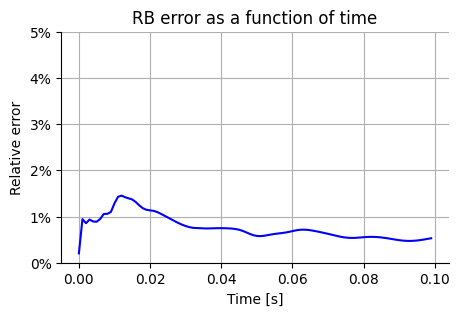

Result of the plot: I have one curve which is representing, for each time instant, the mean of the tests taken into account (15 tests)


In [33]:
# Define the RB error over time
T = dt * steps                                                      # Set the simulation period T = dt * steps
error_over_time = error_each_test.mean(axis = 0)                    # Compute the mean error across test simulations at each time step for plotting
time = np.linspace(0, T, len(error_over_time))                      # Construct the time axis over [0, T] with the same number of points as the error array

# Plot the RB error as a function of time
plt.figure(figsize = (5, 3))
plt.plot(time, error_over_time, 'b')                                # Plot the error as a function of time

# Customize the labels
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("RB error as a function of time")
plt.yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05], ["0%", "1%", "2%" ,"3%", "4%", "5%"])
plt.grid(True)

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


print("Result of the plot: I have one curve which is representing, for each time instant, the mean of the tests taken into account (15 tests)")

In [34]:
print(f"The length of time is {time.shape} i.e. steps + 1 since we have 99 steps + the initial value = 0; we start from 0. This is why we have +1")

The length of time is (100,) i.e. steps + 1 since we have 99 steps + the initial value = 0; we start from 0. This is why we have +1


In [35]:
print(f"{len(error_each_test)}")

15


### 3. Analysis of the spread of the errors along the 15 simulations in the test set

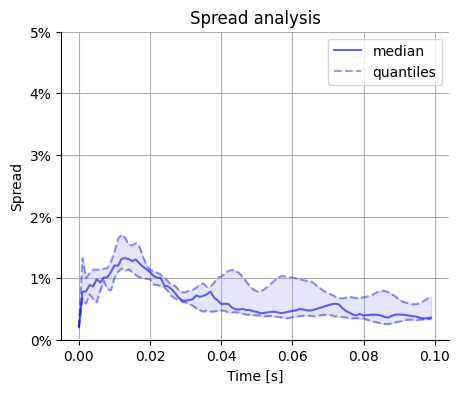

In [36]:
# Define the RB error over time
T = dt * steps                                       # Set the simulation period T = dt * steps (approximately 0.1)
error_each_testT = error_each_test.T
time2 = np.linspace(0, T, len(error_each_testT))      # Construct the time axis over [0, T] with the same number of points as the error array

# Define the statistical measures used to analyze the error distribution
median = np.quantile(error_each_test, 0.5, axis = 0)         # Compute the median
q1 = np.quantile(error_each_test, 0.25, axis = 0)            # First quartile
q3 = np.quantile(error_each_test, 0.75, axis = 0)            # Third quartile
# Plot the error distribution using the median and quantiles; the median is insensitive to outliers, while the quantiles provide a reference interval
plt.figure(figsize = (5, 4))
plt.plot(time2, median, '-b', label = 'median', alpha = 0.6)
plt.plot(time2, q1, '--b', label = 'quantiles', alpha = 0.4)
plt.plot(time2, q3, '--b', alpha = 0.4)
plt.fill_between(time2, q1, q3, color = 'blue', alpha = 0.1)

# # Custom the labels
plt.xlabel("Time [s]")
plt.ylabel("Spread")
plt.title("Spread analysis")
plt.yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05], ["0%", "1%", "2%" ,"3%", "4%", "5%"])
plt.legend()
plt.grid(True)

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

In [37]:
median.shape, q1.shape, q3.shape, errors.shape, time2.shape

((100,), (100,), (100,), (100,), (100,))

In [38]:
time2.shape

(100,)

## Determination of the value of $E$ when $P>50$%

The procedure consists of three steps:
1. A for loop is implemented in which $E$ is increased incrementally. The step size for $E$ is determined using `linspace`. At each iteration, the RBsolver is evaluated for the corresponding value of $E$, and the probability associated with the resulting solution is computed. The results are appended to an array.
2. When the probability exceeds $0.5$, the corresponding values are appended to a second array. The first value in this array identifies the minimum value of $E$ for which $P>0.5$.
3. The arrays `P_total` and `Es_total` are used to plot the system behavior as a function of $E$.

In [39]:
## Probability of having the electron in top region of the plate
if not data_loaded:
  # E = ? such that P >= 0.5? As deltaV0 = 100
  deltaV0_fixed = 100                           # Prescribed value
  E_values = np.linspace(0, 1000, 1000)         # Define the E range; adjust the number of points to change the step size

  # Define the probability array P(Es, deltaV0=100)
  P_results = np.array([[]])

  # Define the E values to be analyzed to identify the threshold for which P > 50%
  Es = np.array([[]])

  # Define the P and E arrays for plotting the probability P(E)
  P_total = np.array([[]])
  Es_total = np.array([[]])

  # Evaluate each value of E
  for E in E_values:
      mu_3 = [E, deltaV0_fixed]                              # Define the parameter vector mu
      psi_reduced_evolution = RBsolver(mu_3)                 # Apply the RB solver for the current E and fixed deltaV0
      probability = probabilities(psi_reduced_evolution)     # Evaluate the probability for the current parameter vector mu_3
      P = caught(probability)
      P_total = np.append(P_total, P)
      Es_total = np.append(Es_total, E)
      if P >= 0.5:
          P_results = np.append(P_results, P)
          Es = np.append(Es, E)

  # Store the values used in the plots
  Es_exceed = Es[0]
  P_exceed = P_results[0]

  print(f" When the probability is of {100*P_exceed:.3f} %, that is the minimum probability for which we have a value of E such that we exceed P = 50%, we expect to have E = {Es_exceed:.3f}" )
else:
    print("Using pre-loaded Es_exceed, P_exceed, P_total, Es_total, P_results from file.")
    Es_exceed = data['Es_exceed']
    P_exceed = data['P_exceed']
    P_total = data['P_total']
    Es_total = data['Es_total']
    P_results = data['P_results']

# Es_fifty = Es[0]
print(f" When the probability is of {100*P_exceed:.3f} %, that is the minimum probability for which we have a value of E such that we exceed P = 50%, we expect to have E = {Es_exceed:.3f}" )

Using pre-loaded Es_exceed, P_exceed, P_total, Es_total, P_results from file.
 When the probability is of 50.045 %, that is the minimum probability for which we have a value of E such that we exceed P = 50%, we expect to have E = 621.622


In [40]:
# E = ? such that P >= 0.5? As deltaV0 = 100
deltaV0_fixed = 100                           # Prescribed value
E_values = np.linspace(0, 1000, 1000)         # Define the E range; adjust the number of points to change the step size

# Define the probability array P(Es, deltaV0=100)
P_results = np.array([[]])

# Define the E values to be analyzed to identify the threshold for which P > 50%
Es = np.array([[]])

# Define the P and E arrays for plotting the probability P(E)
P_total = np.array([[]])
Es_total = np.array([[]])

# Evaluate each value of E
for E in E_values:
    mu_3 = [E, deltaV0_fixed]                              # Define the parameter vector mu
    psi_reduced_evolution = RBsolver(mu_3)                 # Apply the RB solver for the current E and fixed deltaV0
    probability = probabilities(psi_reduced_evolution)     # Evaluate the probability for the current parameter vector mu_3
    P = caught(probability)
    P_total = np.append(P_total, P)
    Es_total = np.append(Es_total, E)
    if P >= 0.5:
        P_results = np.append(P_results, P)
        Es = np.append(Es, E)

# Store the values used in the plots
Es_exceed = Es[0]
P_exceed = P_results[0]

print(f" When the probability is of {100*P_exceed:.3f} %, that is the minimum probability for which we have a value of E such that we exceed P = 50%, we expect to have E = {Es_exceed:.3f}" )

 When the probability is of 50.045 %, that is the minimum probability for which we have a value of E such that we exceed P = 50%, we expect to have E = 621.622


In [41]:
Es_exceed.shape, P_exceed.shape, P_total.shape, Es_total.shape

((), (), (1000,), (1000,))

### How probability varies with the electric field: Plot

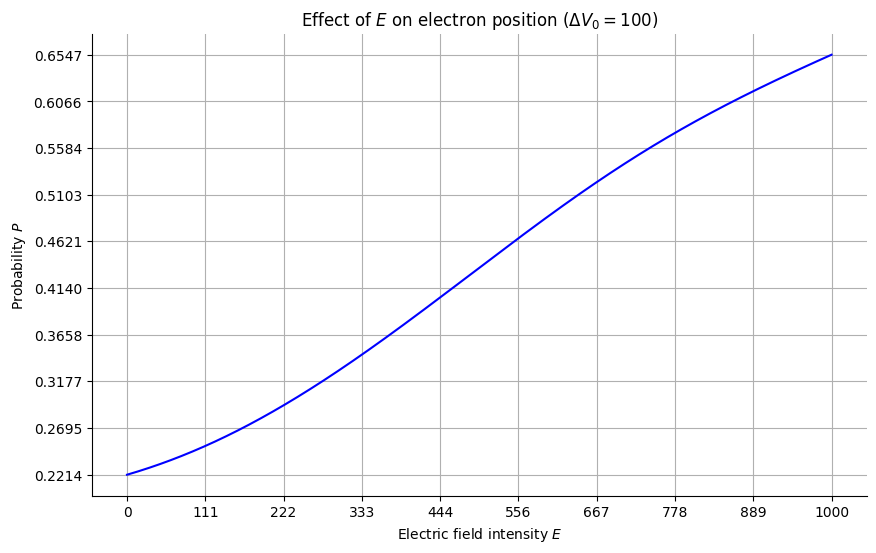

Increasing E pushes the electron toward the upper crystal plate, increasing the probability P. The transition threshold is observed around E≈624.


In [42]:
# Generate the plot
plt.figure(figsize=(10, 6))
plt.plot(Es_total, P_total, 'b-')
# plt.axhline(y=0.5, color='r', linestyle='--', label='50% threshold')
plt.xlabel('Electric field intensity $E$')
plt.ylabel('Probability $P$')
plt.title("Effect of $E$ on electron position ($\\Delta V_0 = 100$)")
plt.grid(True)

# Increase the number of tick marks
plt.xticks(np.linspace(min(Es_total), max(Es_total), 10))
plt.yticks(np.linspace(min(P_total), max(P_total), 10))

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

print("Increasing E pushes the electron toward the upper crystal plate, increasing the probability P. The transition threshold is observed around E≈624.")

## Comparison between the Full Order Model and the Reduced Order Model

Additional plots are included to further investigate the system behavior, assess the reliability of the results, and verify the performance of the RBsolver.
The analyses comprise:
1. Comparison of the animations.
2. Analysis of the error at time steps greater than 99.
3. Error analysis for a parameter value outside the training region.
4. Comparison of FOM and ROM solutions at different time instants.
5. Analysis of the effect of varying $dt$.

The RBsolver is applied in each block. The computational time required for these evaluations is relatively low.

### 1. Comparing the animations

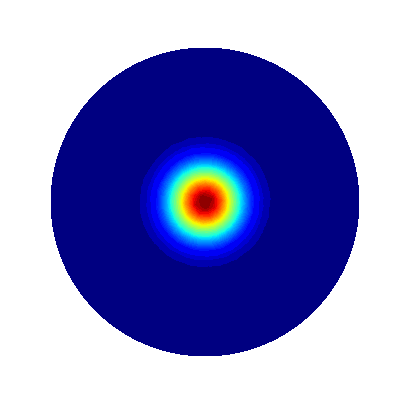

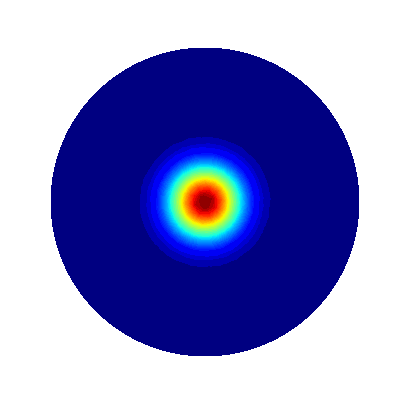

(None, None)

In [43]:
# ROM solution
E_test = 800
deltaV0_test = 50
mutest = np.array([E_test, deltaV0_test])
uRB = RBsolver(mutest, dt, steps)

# FOM solution
u_anim = FOMsolver(800, 50)

# Animation comparing the two solutions
fe.animate(probabilities(u_anim), Vh), fe.animate(probabilities(uRB), Vh)

### 2. Analysis of the error at timesteps > 99

Time-step selection.

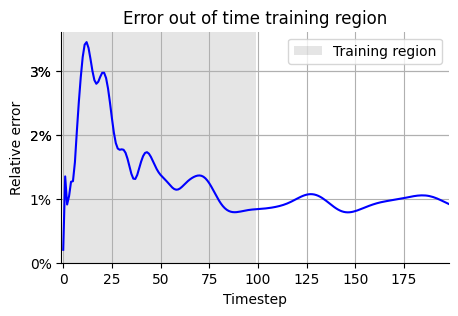

In [44]:
# Apply the FOM and RB solvers over a time interval twice as long as the original one (steps = 198)
steps_exceed = steps * 2
E_exceed = 1000 * np.random.rand()           # Sample E in the range [0, 1000], used here as an approximation of an unbounded range
deltaV0_exceed = 1000 * np.random.rand()     # Sample in the interval [0, 1000]
mu2 = np.array([E_exceed, deltaV0_exceed])
uRB_exceed = RBsolver(mu2, steps=steps_exceed)
uFOM_exceed = FOMsolver(mu2[0], mu2[1], steps_exceed)

# Formula evaluation
error_over_steps = np.linalg.norm(uFOM_exceed-uRB_exceed, axis = 1)/np.linalg.norm(uFOM_exceed, axis = 1)

# Generate plot
plt.figure(figsize = (5, 3))
plt.plot(error_over_steps, 'b')

# Define the plot annotations
plt.xlabel("Timestep")
plt.ylabel("Relative error")
plt.title("Error out of time training region")

# Define the region of interest
marks = np.linspace(error_over_steps.min(), error_over_steps.max(), 6)
marks = [round(mark, 2) for mark in marks]
plt.yticks(marks, [num2p(mark).replace(".00", "") for mark in marks])
ylim = plt.gca().get_ylim()
plt.fill([0, steps, steps, 0], [ylim[0], ylim[0], ylim[1], ylim[1]], 'k', label = "Training region", alpha = 0.1)
plt.axis([-1, steps_exceed, *ylim])
# Customize the plot
plt.grid(True)
plt.legend()

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

Use the time vector as the x-axis.

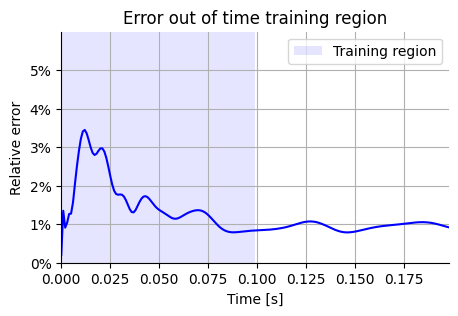

In [45]:
# Apply the FOM and RB solvers over a time interval twice as long as the original one (steps2 = 198)

# Define the time vector
time_exceed = np.linspace(0, steps_exceed * dt, steps_exceed + 1)

# Generate plot
plt.figure(figsize = (5, 3))
plt.plot(time_exceed, error_over_steps, 'b')

# Customize the titles
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("Error out of time training region")
plt.yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05], ["0%", "1%", "2%" ,"3%", "4%", "5%"])

# Set the axis limits
ylim = [0, 0.06]
plt.axis([0, steps_exceed * dt, *ylim])
plt.fill([0, dt*steps, dt*steps, 0], [ylim[0], ylim[0], ylim[1], ylim[1]], 'b', label = "Training region", alpha = 0.1)

# Customize the plot
plt.grid(True)
plt.legend()

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

In [46]:
uRB_exceed.shape, uFOM_exceed.shape

((199, 1990), (199, 1990))

### 3. Error when "ΔV > 1000"

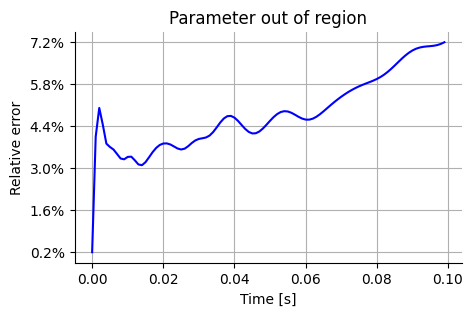

In [47]:
E_out= 1000 * np.random.rand()
deltaV0_out = 2000
mu_out = np.array([E_out, deltaV0_out])
uFOM_out = FOMsolver(mu_out[0], mu_out[1], steps = 99)
uRB_out = RBsolver(mu_out, steps = 99)

error_parameter_change = np.linalg.norm(uFOM_out-uRB_out, axis = 1)/np.linalg.norm(uFOM_out, axis = 1)
plt.figure(figsize = (5, 3))
plt.plot(time, error_parameter_change, 'b')

# Customize the labels
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("Parameter out of region")
marks = np.linspace(error_parameter_change.min(), error_parameter_change.max(), 6)
plt.yticks(marks, [f"{mark:.1%}" for mark in marks])
plt.grid(True)


# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

### 4. Compare different time instants between FOM and ROM

The plots, by using the same parameter for both FOM and ROM for every chosen time instant, are pretty much the same, proving that the solution obtained with the reduced basis is reliable.


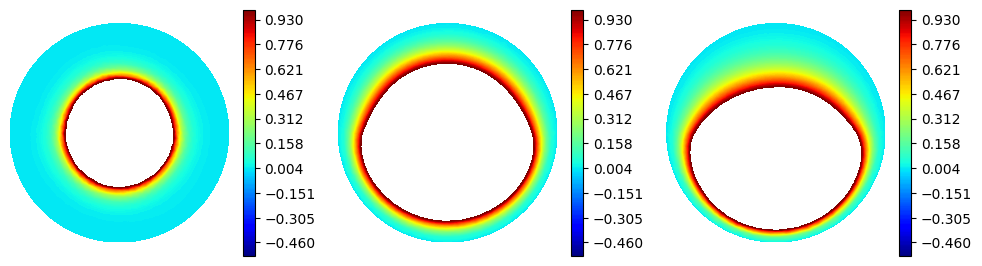

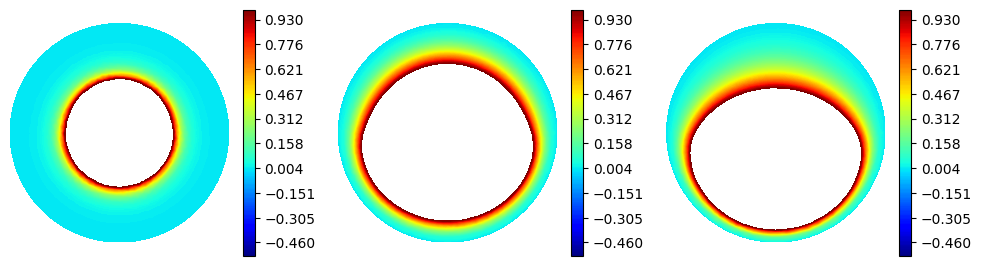

In [48]:
# Define the parameter vector mu
mu_plots_t_instants = [2, 100]

# Compute the RB solution
uRBplots_t_instants = RBsolver(mu_plots_t_instants, dt, steps)
uRBplots_t_instants = fe.multiplot(probabilities(uRBplots_t_instants[[1, 50, 90]]), (1, 3), Vh, colorbar = True, vmin = u.min(), vmax = u.max())

# Compute the FOM solution
uFOMplots_t_instants  = FOMsolver(mu_plots_t_instants[0], mu_plots_t_instants[1])
uFOMplots_t_instants  = fe.multiplot(probabilities(uFOMplots_t_instants[[1, 50, 90]]), (1, 3), Vh, colorbar = True, vmin = u.min(), vmax = u.max())

print("The plots, by using the same parameter for both FOM and ROM for every chosen time instant, are pretty much the same, proving that the solution obtained with the reduced basis is reliable.")

### 5. Varying dt

### dt > 1e-3

In [49]:
dt2 = 1e-3 * 2
Edt = 1000* np.random.rand()                        # Sample E in the range [0, 1000], used here as an approximation of an unbounded range
deltaV0dt = 1000 * np.random.rand()                 # Sample in the interval [0, 1000]
mudt = np.array([Edt, deltaV0dt])                   # Sample the parameter vector used for testing

# The error analysis requires two solutions with the same dimensions
uRBdt = RBsolver(mudt, dt2, steps)
uFOMdt = FOMsolver(mudt[0], mudt[1], steps = steps, dt = dt2)
uRBdt.shape, uFOMdt.shape

((100, 1990), (100, 1990))

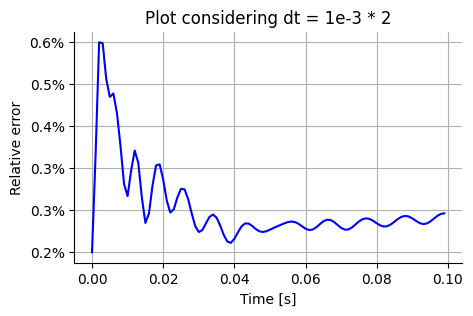

In [50]:
# Define the RB error over time
error_dt = np.linalg.norm(uFOMdt-uRBdt, axis = -1)/np.linalg.norm(uFOMdt, axis = -1)

# Plot the RB error as a function of time
plt.figure(figsize = (5, 3))
plt.plot(time, error_dt, 'b')                                # Plot the error as a function of time

# Customize the labels
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("Plot considering dt = 1e-3 * 2")
marks = np.linspace(error_dt.min(), error_dt.max(), 6)
plt.yticks(marks, [f"{mark:.1%}" for mark in marks])
plt.grid(True)

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

### dt < 1e-3

In [51]:
dt3 = 1e-3 / 2
Edt2 = 1000* np.random.rand()                        # Sample E in the range [0, 1000], used here as an approximation of an unbounded range
deltaV0dt2 = 1000 * np.random.rand()                 # Sample in the interval [0, 1000]
mudt2 = np.array([Edt2, deltaV0dt2])                   # Sample the parameter vector used for testing

# The error analysis requires two solutions with the same dimensions
uRBdt2 = RBsolver(mudt2, dt3, steps)
uFOMdt2 = FOMsolver(mudt2[0], mudt2[1], steps = 99 , dt = dt3)
uRBdt2.shape, uFOMdt2.shape

((100, 1990), (100, 1990))

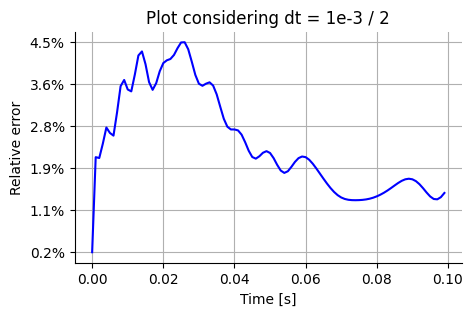

In [52]:
# Define the RB error over time
error_dt2 = np.linalg.norm(uFOMdt2-uRBdt2, axis = -1)/np.linalg.norm(uFOMdt2, axis = -1)

# Plot the RB error as a function of time
plt.figure(figsize = (5, 3))
plt.plot(time, error_dt2, 'b')                                # Plot the error as a function of time

# Customize the labels
plt.xlabel("Time [s]")
plt.ylabel("Relative error")
plt.title("Plot considering dt = 1e-3 / 2")
marks = np.linspace(error_dt2.min(), error_dt2.max(), 6)
plt.yticks(marks, [f"{mark:.1%}" for mark in marks])
plt.grid(True)

# Remove the axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()